In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('emails.csv')

In [3]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [4]:
df.describe()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


In [6]:
df.isnull().sum()

Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [7]:
df = df.drop_duplicates()
df = df.dropna()

In [8]:
df.isnull().sum()

Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [9]:
str_col = df.select_dtypes(include=['str'])

TypeError: string dtypes are not allowed, use 'object' instead

In [ ]:
print(str_col)

In [10]:
# Preparing the data
X = df.drop(columns=['Email No.','Prediction'])
Y = df['Prediction']

from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [11]:
# Scaling the features

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [12]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

In [21]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

knn_model = KNeighborsClassifier(n_neighbors=5)

In [22]:
knn_model.fit(x_train,y_train)

KNeighborsClassifier()

In [23]:
y_pred = knn_model.predict(x_test)

In [24]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [25]:
print("KNN Classification Report")
print(classification_report(y_test, y_pred))

KNN Classification Report
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       739
           1       0.73      0.84      0.78       296

    accuracy                           0.86      1035
   macro avg       0.83      0.86      0.84      1035
weighted avg       0.87      0.86      0.87      1035



In [26]:
print("KNN Accuracy :")
print(accuracy_score(y_test, y_pred))

KNN Accuracy :
0.863768115942029


0.863768115942029
0.13623188405797101
0.7272727272727273
0.8378378378378378
0.7786499215070644


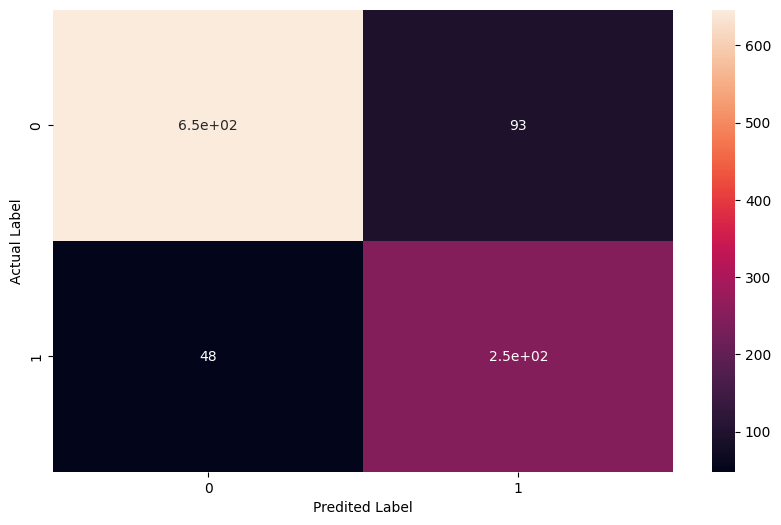

In [27]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(10,6))
sns.heatmap(cm,annot=True)
plt.xlabel("Predited Label")
plt.ylabel("Actual Label")

tn,fp,fn,tp = cm.ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1_score = (2 * precision * recall / (precision + recall)
            if (precision + recall) else 0)
error_rate = (fp + fn) / (tp + tn + fp + fn)

print(accuracy)
print(error_rate)
print(precision)
print(recall)
print(f1_score)

In [29]:
from sklearn.svm import SVC
svm_model = SVC(kernel='linear')
svm_model.fit(x_train_scaled, y_train)

SVC(kernel='linear')

In [32]:
y_pred_svm = svm_model.predict(x_test_scaled)

In [33]:
print("SVM Classification Report")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       739
           1       0.90      0.92      0.91       296

    accuracy                           0.95      1035
   macro avg       0.93      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [34]:
print("SVM Accuracy :")
print(accuracy_score(y_test, y_pred_svm))

SVM Accuracy :
0.9468599033816425


0.9468599033816425
0.05314009661835749
0.8950819672131147
0.9222972972972973
0.908485856905158


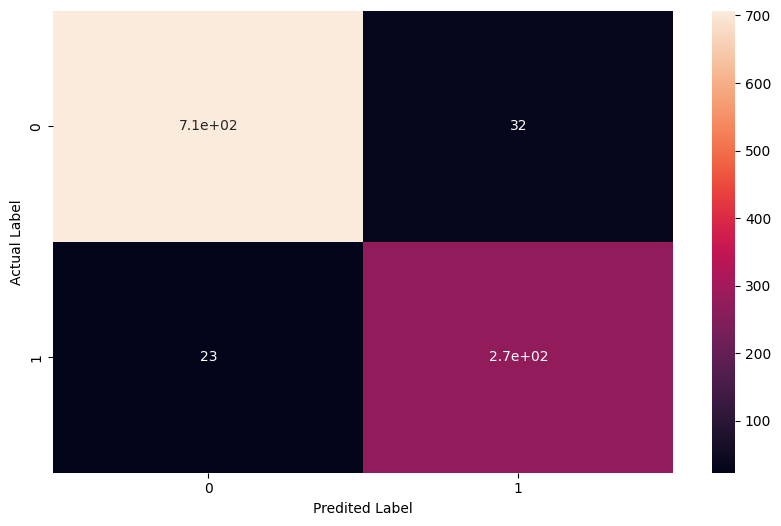

In [35]:
cm = confusion_matrix(y_test,y_pred_svm)
plt.figure(figsize=(10,6))
sns.heatmap(cm,annot=True)
plt.xlabel("Predited Label")
plt.ylabel("Actual Label")

tn,fp,fn,tp = cm.ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1_score = (2 * precision * recall / (precision + recall)
            if (precision + recall) else 0)
error_rate = (fp + fn) / (tp + tn + fp + fn)

print(accuracy)
print(error_rate)
print(precision)
print(recall)
print(f1_score)

In [36]:
from sklearn.metrics import roc_auc_score

In [37]:
print("KNN ROC_AUC :")
print(roc_auc_score(y_test, y_pred))
print("\n")
print("SVM ROC_AUC :")
print(roc_auc_score(y_test, y_pred_svm))

KNN ROC_AUC :
0.8559960501773762


SVM ROC_AUC :
0.9394977690816663
